# Etapa 4: Random Tree

Entrada: as mesmas linhas completas de `data/processed/chembl_4targets.csv` usadas no notebook 03, com os 17 atributos e a divisão agrupada.

A Random Tree é uma árvore de decisão que, em cada nó, sorteia K atributos e escolhe a melhor pergunta só entre eles. No scikit-learn, é o `DecisionTreeClassifier` com `max_features=K`.


## 0. Configuração

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

from src import modeling
from src.config import FINAL_CSV, FEATURE_SETS

final = pd.read_csv(FINAL_CSV)
dados = modeling.prepare(final)

## 1. Treino e teste

Mesma divisão agrupada do notebook 03: moléculas com descritores idênticos nunca ficam em lados opostos.

In [2]:
atributos = FEATURE_SETS["descritores + SMILES"]
treino, teste = dados.splits["agrupada"]

X_treino = dados.X[atributos].iloc[treino]
X_teste = dados.X[atributos].iloc[teste]
y_treino = dados.y.iloc[treino]
y_teste = dados.y.iloc[teste]

print(X_treino.shape, X_teste.shape)

(21980, 17) (5496, 17)


## 2. Árvore de decisão × Random Tree

As duas usam os hiperparâmetros escolhidos no notebook 03 (entropia, sem limite de profundidade, sem poda). A única diferença é `max_features`: a árvore testa os 17 atributos em cada nó, e a Random Tree sorteia 5. A função `avaliar` treina um modelo e resume a acurácia, o tamanho e a pergunta da raiz.

In [3]:
def avaliar(modelo):
    modelo.fit(X_treino, y_treino)
    return {
        "acurácia treino": accuracy_score(y_treino, modelo.predict(X_treino)),
        "acurácia teste": accuracy_score(y_teste, modelo.predict(X_teste)),
        "folhas": modelo.get_n_leaves(),
        "profundidade": modelo.get_depth(),
        "atributo da raiz": atributos[modelo.tree_.feature[0]],
        "limiar da raiz": modelo.tree_.threshold[0],
    }

In [4]:
arvore = DecisionTreeClassifier(criterion="entropy", random_state=42)
random_tree = DecisionTreeClassifier(criterion="entropy", max_features=5, random_state=42)

resultados = pd.DataFrame({
    "Árvore de decisão": avaliar(arvore),
    "Random Tree (K=5)": avaliar(random_tree),
})
resultados

,Árvore de decisão,Random Tree (K=5)
acurácia treino,1.0,1.0
acurácia teste,0.896652,0.88246
folhas,1854,2559
profundidade,24,23
atributo da raiz,TPSA,HBD
limiar da raiz,67.895,1.5


**Resultado.** A árvore de decisão reproduz o notebook 03 (0,897; 1.854 folhas; raiz TPSA ≤ 67,9). A Random Tree com K=5 acerta 0,882 no teste, 1,4 ponto a menos, e precisa de 38% mais folhas (2.559), porque, sem o melhor atributo em todos os nós, cada pergunta separa as classes um pouco pior. A profundidade quase não muda (23 contra 24).

A raiz passou a ser HBD ≤ 1,5: a TPSA não foi sorteada (chance de 5 em 17), e a árvore usou um atributo correlacionado, que também mede polaridade. Este é um resultado de uma semente só; a variação entre sementes é medida na seção 4.

## 3. Qual é o melhor K?

Acurácia de treino e de validação cruzada (5 partes agrupadas, dentro do treino) para K = 1, 2, 3, 5, 8, 12 e 17. K = 17 é a árvore de decisão. O conjunto de teste não é usado nesta escolha.

`validation_curve` treina, para cada K, uma árvore em cada uma das 5 partes da validação cruzada. As partes respeitam os grupos de descritores idênticos, como no notebook 03.

In [5]:
from sklearn.model_selection import StratifiedGroupKFold, validation_curve
from src.config import CV_FOLDS

valores_k = [1, 2, 3, 5, 8, 12, 17]
grupos_treino = dados.grupos[treino]
cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=42)

acc_treino, acc_validacao = validation_curve(
    DecisionTreeClassifier(criterion="entropy", random_state=42),
    X_treino, y_treino,
    param_name="max_features", param_range=valores_k,
    groups=grupos_treino, cv=cv, n_jobs=-1,
)

curva_k = pd.DataFrame({
    "K": valores_k,
    "treino": acc_treino.mean(axis=1),
    "validação": acc_validacao.mean(axis=1),
    "desvio validação": acc_validacao.std(axis=1),
})
curva_k

,K,treino,validação,desvio validação
0,1,1.0,0.797771,0.006596
1,2,1.0,0.836715,0.008119
2,3,1.0,0.858053,0.008014
3,5,1.0,0.870928,0.010323
4,8,1.0,0.874340,0.007257
5,12,1.0,0.872384,0.010540
6,17,1.0,0.878344,0.005134


A curva de validação traz uma barra com o desvio entre as 5 partes.

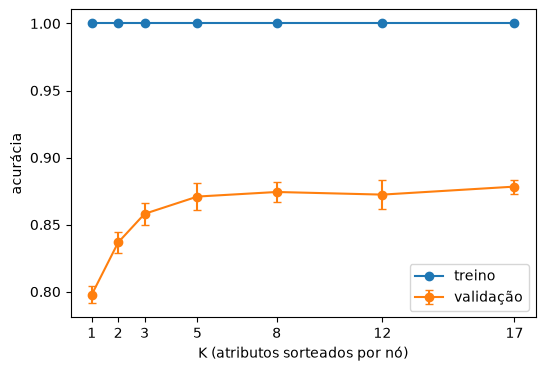

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(curva_k["K"], curva_k["treino"], marker="o", label="treino")
ax.errorbar(curva_k["K"], curva_k["validação"], yerr=curva_k["desvio validação"],
            marker="o", capsize=3, label="validação")
ax.set_xlabel("K (atributos sorteados por nó)")
ax.set_ylabel("acurácia")
ax.set_xticks(valores_k)
ax.legend()
plt.show()

**Resultado.** A acurácia de treino é 100% para todo K: sem limite de profundidade, a árvore divide até as folhas ficarem puras. A validação sobe rápido de K=1 (0,798) a K=5 (0,871) e forma um platô: de K=5 a K=17 (0,878, igual ao notebook 03) as diferenças são menores que 1 ponto, do tamanho do desvio entre as partes da validação cruzada.

Para uma árvore sozinha, sortear atributos não melhora a acurácia; no máximo empata. A partir de K=5 a aleatoriedade custa menos de 1 ponto. Os próximos experimentos usam K=5.


## 4. Instabilidade: a mesma Random Tree com 30 sementes

A Random Tree (K=5) e a árvore de decisão são treinadas 30 vezes nos mesmos dados, mudando apenas `random_state`. Medem-se a variação da acurácia de teste, o atributo da raiz e se as árvores erram nas mesmas moléculas.

São 60 árvores (2 modelos × 30 sementes). As previsões de cada Random Tree no teste ficam guardadas em `previsoes` para a análise de erros abaixo.

In [7]:
linhas = []
previsoes = {}

for semente in range(30):
    for nome, k in [("Árvore de decisão", None), ("Random Tree (K=5)", 5)]:
        modelo = DecisionTreeClassifier(criterion="entropy", max_features=k, random_state=semente)
        resultado = avaliar(modelo)
        resultado["modelo"] = nome
        resultado["semente"] = semente
        linhas.append(resultado)
        if k == 5:
            previsoes[semente] = modelo.predict(X_teste)

sementes_df = pd.DataFrame(linhas)
sementes_df.head()

,acurácia treino,acurácia teste,folhas,profundidade,atributo da raiz,limiar da raiz,modelo,semente
0,1.0,0.898108,1854,24,TPSA,67.895,Árvore de decisão,0
1,1.0,0.860626,2719,22,TPSA,67.895,Random Tree (K=5),0
2,1.0,0.896288,1853,24,TPSA,67.895,Árvore de decisão,1
3,1.0,0.866812,2653,23,n_aromatic,13.500,Random Tree (K=5),1
4,1.0,0.895560,1852,24,TPSA,67.895,Árvore de decisão,2


Média, desvio, mínimo e máximo da acurácia e do número de folhas, e quantas vezes cada atributo ficou na raiz.

In [8]:
resumo = sementes_df.groupby("modelo")[["acurácia teste", "folhas"]].agg(["mean", "std", "min", "max"])
display(resumo)
display(sementes_df.groupby("modelo")["atributo da raiz"].value_counts())

acurácia teste                                     folhas  \
                            mean       std       min       max         mean   
modelo                                                                        
Random Tree (K=5)       0.875619  0.008428  0.857897  0.888464  2582.100000   
Árvore de decisão       0.895008  0.002037  0.891921  0.898472  1852.933333   

                                          
                         std   min   max  
modelo                                    
Random Tree (K=5)  91.865475  2447  2805  
Árvore de decisão   2.116167  1848  1858

modelo             atributo da raiz
Random Tree (K=5)  TPSA                 9
                   n_double             6
                   n_aromatic           4
                   HBD                  3
                   n_branch             3
                   n_N                  1
                   smiles_len           1
                   n_stereo             1
                   n_halogen            1
                   HBA                  1
Árvore de decisão  TPSA                30
Name: count, dtype: int64

As árvores erram nas mesmas moléculas? Para cada molécula de teste, conta-se quantas das 30 Random Trees a acertaram (de 0 a 30).

In [9]:
acertos = pd.DataFrame({s: p == y_teste.to_numpy() for s, p in previsoes.items()})
n_acertos = acertos.sum(axis=1)

distribuicao = n_acertos.value_counts().sort_index()
distribuicao

0       11
1       13
2        5
3       15
4       15
5       24
6       20
7       25
8       13
9       21
10      24
11      36
12      38
13      33
14      48
15      43
16      56
17      63
18      63
19      65
20      87
21     118
22     111
23     138
24     161
25     202
26     248
27     341
28     512
29     787
30    2160
Name: count, dtype: int64

Se as árvores errassem sempre nas mesmas moléculas, só haveria barras em 0 e 30. O eixo vertical é logarítmico para que as barras pequenas apareçam.

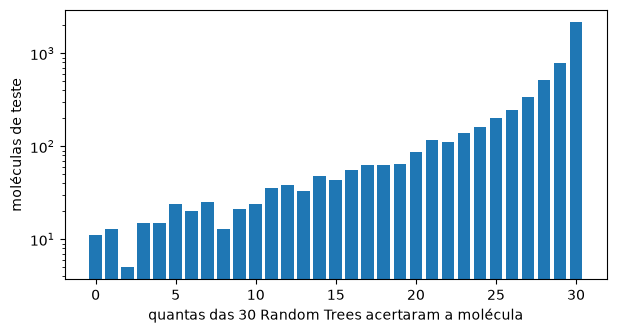

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(distribuicao.index, distribuicao.values)
ax.set_xlabel("quantas das 30 Random Trees acertaram a molécula")
ax.set_ylabel("moléculas de teste")
ax.set_yscale("log")
plt.show()

**Resultado.** Nas 30 sementes, a árvore de decisão fica entre 0,892 e 0,898 (desvio de 0,2 ponto) e sempre tem TPSA ≤ 67,9 na raiz: a semente só desempata perguntas igualmente boas nos nós mais fundos. A Random Tree (K=5) varia quatro vezes mais, de 0,858 a 0,888 (desvio de 0,8 ponto), com média de 0,876. A TPSA é a raiz em 9 das 30 (30%, contra 29% esperados) e aparecem 10 raízes diferentes.

As Random Trees erram em moléculas diferentes: só 11 das 5.496 moléculas de teste são erradas pelas 30 árvores, 2.160 são acertadas por todas e cerca de 60% ficam no meio. Como só 384 moléculas têm 15 acertos ou menos, a votação das 30 árvores acertaria pelo menos 93,0%.

## 5. Votação: de uma Random Tree à Random Forest

Conjuntos de 1 a 300 Random Trees (K=5, entropia) votando juntas, com e sem bootstrap. Sem bootstrap, as árvores só diferem pelo sorteio de atributos; com bootstrap, cada uma treina numa amostra com reposição diferente, que é a Random Forest completa.

O `RandomForestClassifier` com `max_features=5` e `criterion="entropy"` é exatamente um conjunto das Random Trees acima; `bootstrap` liga ou desliga a amostragem com reposição. Como as folhas são puras, a média das probabilidades que ele calcula equivale à votação.

In [11]:
import time
from sklearn.ensemble import RandomForestClassifier

quantidades = [1, 5, 10, 30, 100, 300]
linhas_votacao = []

for bootstrap in [False, True]:
    for n in quantidades:
        floresta = RandomForestClassifier(
            n_estimators=n, criterion="entropy", max_features=5,
            bootstrap=bootstrap, random_state=42, n_jobs=-1,
        )
        inicio = time.perf_counter()
        floresta.fit(X_treino, y_treino)
        tempo = time.perf_counter() - inicio
        linhas_votacao.append({
            "bootstrap": "com bootstrap" if bootstrap else "sem bootstrap",
            "árvores": n,
            "acurácia teste": accuracy_score(y_teste, floresta.predict(X_teste)),
            "tempo de treino (s)": round(tempo, 2),
        })

votacao = pd.DataFrame(linhas_votacao)
votacao.pivot(index="árvores", columns="bootstrap", values="acurácia teste")

bootstrap,com bootstrap,sem bootstrap
árvores,,
1,0.855531,0.882278
5,0.921761,0.935226
10,0.936499,0.942322
30,0.946143,0.951783
100,0.951419,0.954694
300,0.952875,0.955968


As linhas cinza são as médias da seção 4: a árvore de decisão e uma Random Tree sozinha.

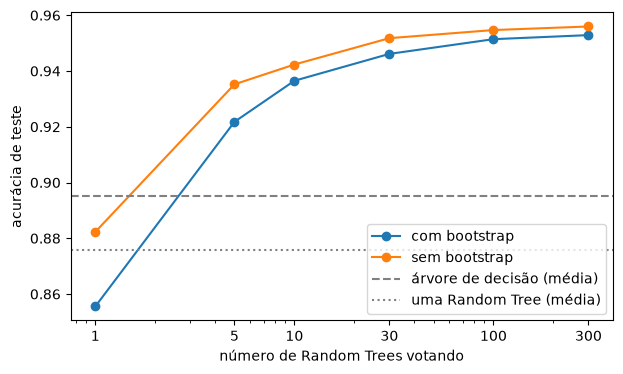

In [12]:
medias = sementes_df.groupby("modelo")["acurácia teste"].mean()

fig, ax = plt.subplots(figsize=(7, 4))
for nome, grupo in votacao.groupby("bootstrap"):
    ax.plot(grupo["árvores"], grupo["acurácia teste"], marker="o", label=nome)
ax.axhline(medias["Árvore de decisão"], color="gray", linestyle="--", label="árvore de decisão (média)")
ax.axhline(medias["Random Tree (K=5)"], color="gray", linestyle=":", label="uma Random Tree (média)")
ax.set_xscale("log")
ax.set_xticks(quantidades)
ax.set_xticklabels(quantidades)
ax.set_xlabel("número de Random Trees votando")
ax.set_ylabel("acurácia de teste")
ax.legend()
plt.show()

**Resultado.** Cinco Random Trees votando já chegam a 0,935 sem bootstrap, acima da árvore de decisão (0,895). Com 300 árvores, a votação chega a 0,956 sem bootstrap e 0,953 com bootstrap; esta última fica no mesmo nível da Random Forest do notebook 03 (0,952). O ganho achata a partir de 100 árvores: de 100 para 300 a acurácia sobe no máximo 0,3 ponto.

O bootstrap não ajuda nesta base. Cada amostra com reposição deixa de fora cerca de 37% das moléculas, e cada árvore fica mais fraca (0,856 contra 0,882 com uma árvore só); a diversidade que o bootstrap traria já vem do sorteio de atributos. Com poucas árvores, a versão sem bootstrap vence por 0,6 a 2,7 pontos; com 300, a diferença nesta divisão é de 0,3 ponto, e a seção 7 mostra que, nas 10 divisões, ela é consistente (0,5 ponto, positiva em todas). O ganho da Random Forest vem, sobretudo, do sorteio de atributos com votação.

## 6. Comparação final em 10 divisões

Os quatro modelos são treinados e avaliados nas mesmas 10 divisões agrupadas (seeds 0 a 9) usadas no relatório da atividade 1. Reportam-se média e desvio da acurácia, do F1 macro e do tempo de treino.

Em cada semente, `modeling.prepare` gera outra divisão agrupada, e os quatro modelos são treinados do zero. As florestas usam todos os núcleos do processador (`n_jobs=-1`) e as árvores únicas, um só; a comparação de tempo favorece as florestas.

In [13]:
from sklearn.metrics import f1_score

def modelos_comparados(semente):
    return {
        "Árvore de decisão": DecisionTreeClassifier(criterion="entropy", random_state=semente),
        "Random Tree (K=5)": DecisionTreeClassifier(criterion="entropy", max_features=5, random_state=semente),
        "300 Random Trees sem bootstrap": RandomForestClassifier(
            n_estimators=300, criterion="entropy", max_features=5, bootstrap=False,
            random_state=semente, n_jobs=-1),
        "Random Forest da atividade 1": RandomForestClassifier(
            n_estimators=300, random_state=semente, n_jobs=-1),
    }

linhas_finais = []
for semente in range(10):
    dados_s = modeling.prepare(final, seed=semente)
    tr, te = dados_s.splits["agrupada"]
    X_tr, X_te = dados_s.X[atributos].iloc[tr], dados_s.X[atributos].iloc[te]
    y_tr, y_te = dados_s.y.iloc[tr], dados_s.y.iloc[te]

    for nome, modelo in modelos_comparados(semente).items():
        inicio = time.perf_counter()
        modelo.fit(X_tr, y_tr)
        tempo = time.perf_counter() - inicio
        previsto = modelo.predict(X_te)
        linhas_finais.append({
            "semente": semente,
            "modelo": nome,
            "acurácia": accuracy_score(y_te, previsto),
            "F1 macro": f1_score(y_te, previsto, average="macro"),
            "tempo de treino (s)": tempo,
        })

comparacao_final = pd.DataFrame(linhas_finais)
comparacao_final.groupby("modelo", sort=False)[["acurácia", "F1 macro", "tempo de treino (s)"]].agg(["mean", "std"]).round(3)

acurácia        F1 macro         \
                                   mean    std     mean    std   
modelo                                                           
Árvore de decisão                 0.895  0.005    0.893  0.005   
Random Tree (K=5)                 0.876  0.011    0.875  0.011   
300 Random Trees sem bootstrap    0.957  0.002    0.956  0.002   
Random Forest da atividade 1      0.952  0.003    0.951  0.003   

                               tempo de treino (s)         
                                              mean    std  
modelo                                                     
Árvore de decisão                            0.102  0.002  
Random Tree (K=5)                            0.041  0.002  
300 Random Trees sem bootstrap               1.315  0.065  
Random Forest da atividade 1                 0.744  0.022

Comparação pareada: na mesma semente, os dois modelos são avaliados no mesmo treino e no mesmo teste. A diferença dentro de cada divisão elimina a variação que vem da divisão em si.

In [14]:
pares = comparacao_final.pivot(index="semente", columns="modelo", values="acurácia")
pares["diferença"] = pares["300 Random Trees sem bootstrap"] - pares["Random Forest da atividade 1"]

display(pares[["300 Random Trees sem bootstrap", "Random Forest da atividade 1", "diferença"]].round(4))
print("Divisões em que a versão sem bootstrap venceu:", (pares["diferença"] > 0).sum(), "de 10")

modelo,300 Random Trees sem bootstrap,Random Forest da atividade 1,diferença
semente,,,
0,0.9565,0.9514,0.0051
1,0.9572,0.9485,0.0087
2,0.9567,0.9538,0.0029
3,0.9541,0.9498,0.0044
4,0.9558,0.9507,0.0051
5,0.9616,0.9580,0.0036
6,0.9567,0.9505,0.0062
7,0.9540,0.9498,0.0042
8,0.9587,0.9534,0.0053


Divisões em que a versão sem bootstrap venceu: 10 de 10


**Resultado.** Nas 10 divisões, a ordem é: Random Tree (0,876 ± 0,011), árvore de decisão (0,895 ± 0,005), Random Forest da atividade 1 (0,952 ± 0,003) e 300 Random Trees sem bootstrap (0,957 ± 0,002). A árvore e a Random Forest reproduzem o relatório da atividade 1. O F1 macro acompanha a acurácia em todos os modelos.

Uma Random Tree sozinha é o modelo mais instável (desvio de 1,1 ponto, o dobro da árvore de decisão), e 300 delas votando formam o mais estável (0,2 ponto): a votação reduz a variância. A Random Tree treina 2,5 vezes mais rápido que a árvore de decisão (0,04 s contra 0,10 s), porque avalia 5 atributos por nó em vez de 17.

As 300 Random Trees sem bootstrap superam a Random Forest padrão nas 10 divisões, por 0,3 a 0,9 ponto. As duas diferem no bootstrap, no critério (entropia contra Gini) e em K (5 contra 4), então a vantagem não se deve só ao bootstrap; a seção 7 separa quanto dessa vantagem vem do bootstrap e quanto vem do critério e de K.

## 7. O papel do bootstrap

Dois testes complementares. O primeiro mostra quando o bootstrap ajuda: com K=17 não há sorteio de atributos, e a única fonte de diversidade entre as árvores é o bootstrap. O segundo separa, nas 10 divisões, quanto da vantagem sobre a Random Forest padrão vem do bootstrap e quanto vem do critério e de K.

### Teste 1: bootstrap com e sem sorteio de atributos

Tabela 2 × 2 com 300 árvores na divisão principal: K=5 ou K=17 (todos os atributos), com ou sem bootstrap.

In [15]:
linhas_2x2 = []
for k in [5, None]:
    for bootstrap in [False, True]:
        floresta = RandomForestClassifier(
            n_estimators=300, criterion="entropy", max_features=k,
            bootstrap=bootstrap, random_state=42, n_jobs=-1,
        )
        floresta.fit(X_treino, y_treino)
        linhas_2x2.append({
            "atributos por nó": "K = 5 (sorteio)" if k == 5 else "K = 17 (todos)",
            "bootstrap": "com bootstrap" if bootstrap else "sem bootstrap",
            "acurácia teste": accuracy_score(y_teste, floresta.predict(X_teste)),
        })

tabela_2x2 = pd.DataFrame(linhas_2x2).pivot(index="atributos por nó", columns="bootstrap", values="acurácia teste")
tabela_2x2.round(4)

bootstrap,com bootstrap,sem bootstrap
atributos por nó,,
K = 17 (todos),0.9378,0.9016
K = 5 (sorteio),0.9529,0.9560


### Teste 2: separar os efeitos nas 10 divisões

A diferença entre a Random Forest padrão e as 300 Random Trees sem bootstrap é dividida em dois degraus, cada um mudando uma coisa só: (1) trocar o critério e K, mantendo o bootstrap; (2) tirar o bootstrap.

In [16]:
linhas_bootstrap = []
for semente in range(10):
    dados_s = modeling.prepare(final, seed=semente)
    tr, te = dados_s.splits["agrupada"]
    X_tr, X_te = dados_s.X[atributos].iloc[tr], dados_s.X[atributos].iloc[te]
    y_tr, y_te = dados_s.y.iloc[tr], dados_s.y.iloc[te]

    modelo = RandomForestClassifier(
        n_estimators=300, criterion="entropy", max_features=5, bootstrap=True,
        random_state=semente, n_jobs=-1,
    )
    modelo.fit(X_tr, y_tr)
    linhas_bootstrap.append({"semente": semente, "acurácia": accuracy_score(y_te, modelo.predict(X_te))})

pares["300 Random Trees com bootstrap"] = pd.DataFrame(linhas_bootstrap).set_index("semente")["acurácia"]
pares["degrau 1: critério e K"] = pares["300 Random Trees com bootstrap"] - pares["Random Forest da atividade 1"]
pares["degrau 2: tirar o bootstrap"] = pares["300 Random Trees sem bootstrap"] - pares["300 Random Trees com bootstrap"]

degraus = ["degrau 1: critério e K", "degrau 2: tirar o bootstrap"]
display(pares[degraus].round(4))
display(pares[degraus].agg(["mean", "std"]).round(4))
for degrau in degraus:
    print(f"{degrau}: positivo em {(pares[degrau] > 0).sum()} de 10 divisões")

modelo,degrau 1: critério e K,degrau 2: tirar o bootstrap
semente,,
0,0.0015,0.0036
1,0.0029,0.0058
2,-0.0007,0.0036
3,0.0018,0.0025
4,0.0011,0.0040
5,-0.0016,0.0053
6,0.0005,0.0056
7,0.0002,0.0040
8,-0.0016,0.0069


modelo,degrau 1: critério e K,degrau 2: tirar o bootstrap
mean,0.0005,0.0048
std,0.0015,0.0015


degrau 1: critério e K: positivo em 7 de 10 divisões
degrau 2: tirar o bootstrap: positivo em 10 de 10 divisões


**Resultado.** Com K=17 não há sorteio de atributos: sem bootstrap, as 300 árvores são praticamente cópias da árvore de decisão e a votação fica em 0,902; com bootstrap, sobe para 0,938 (+3,6 pontos). Com K=5, o bootstrap deixa de ajudar (0,956 sem, contra 0,953 com). Bootstrap e sorteio de atributos são duas fontes de diversidade: o bootstrap é essencial quando é a única, e sobra quando o sorteio de atributos já existe. Nesta base, o sorteio sozinho (0,956) gera mais diversidade útil que o bootstrap sozinho (0,938).

Nas 10 divisões, a vantagem de 0,5 ponto sobre a Random Forest padrão se divide em dois degraus: trocar o critério e K rende +0,05 ± 0,15 ponto (positivo em 7 de 10, ruído); tirar o bootstrap rende +0,48 ± 0,15 ponto (positivo em 10 de 10). Cerca de 90% da vantagem vem de dispensar o bootstrap, que deixa cada árvore com cerca de 63% das moléculas de treino.

## 8. Onde cada modelo acerta e erra

Na divisão principal (seed 42): F1 por classe, matriz de confusão, o par HDAC1 ↔ EGFR e a importância dos atributos, comparando a árvore de decisão, uma Random Tree (K=5) e 300 Random Trees votando (K=5, sem bootstrap).

F1 por classe dos três modelos.

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay
from src.config import CLASSES

modelos_finais = {
    "Árvore de decisão": DecisionTreeClassifier(criterion="entropy", random_state=42),
    "Random Tree (K=5)": DecisionTreeClassifier(criterion="entropy", max_features=5, random_state=42),
    "300 Random Trees": RandomForestClassifier(
        n_estimators=300, criterion="entropy", max_features=5, bootstrap=False,
        random_state=42, n_jobs=-1),
}

previsoes_finais = {}
for nome, modelo in modelos_finais.items():
    modelo.fit(X_treino, y_treino)
    previsoes_finais[nome] = modelo.predict(X_teste)

f1_por_classe = pd.DataFrame(
    {nome: f1_score(y_teste, prev, labels=CLASSES, average=None) for nome, prev in previsoes_finais.items()},
    index=CLASSES,
)
f1_por_classe.round(3)

,Árvore de decisão,Random Tree (K=5),300 Random Trees
EGFR,0.888,0.875,0.953
BACE1,0.911,0.892,0.962
DRD2,0.916,0.900,0.965
HDAC1,0.868,0.861,0.942


Matrizes de confusão, cada linha normalizada pela classe real.

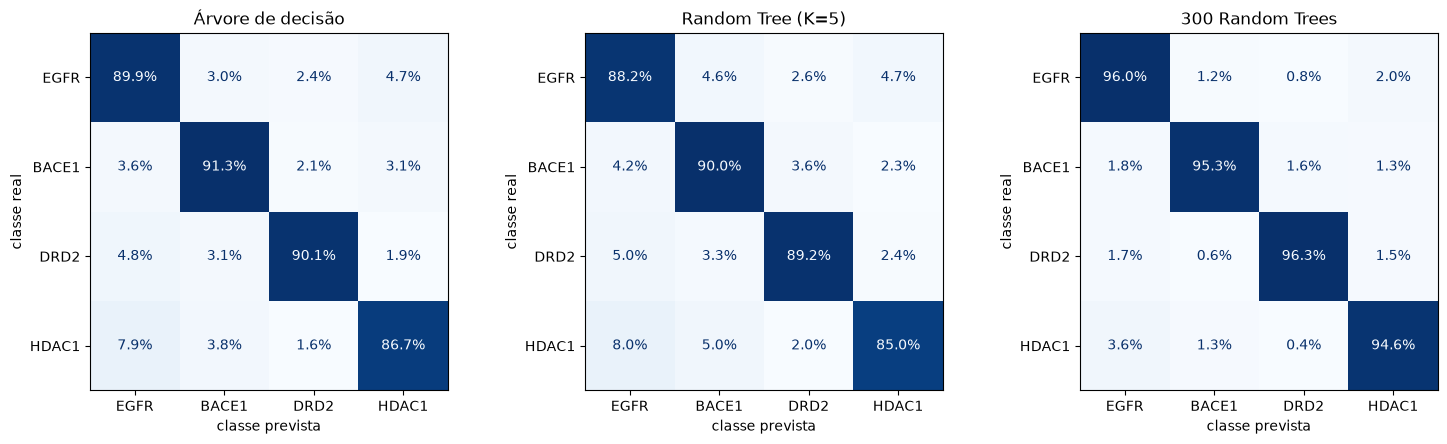

In [18]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (nome, prev) in zip(eixos, previsoes_finais.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_teste, prev, labels=CLASSES, normalize="true",
        values_format=".1%", cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(nome)
    ax.set_xlabel("classe prevista")
    ax.set_ylabel("classe real")
plt.tight_layout()
plt.show()

O par HDAC1 ↔ EGFR, a principal confusão da árvore no notebook 03.

In [19]:
real = y_teste.to_numpy()
linhas_par = []
for nome, prev in previsoes_finais.items():
    erros = (real != prev).sum()
    hdac_para_egfr = ((real == "HDAC1") & (prev == "EGFR")).sum()
    egfr_para_hdac = ((real == "EGFR") & (prev == "HDAC1")).sum()
    linhas_par.append({
        "modelo": nome,
        "erros": erros,
        "HDAC1 → EGFR": hdac_para_egfr,
        "EGFR → HDAC1": egfr_para_hdac,
        "% dos erros no par": round(100 * (hdac_para_egfr + egfr_para_hdac) / erros, 1),
    })
pd.DataFrame(linhas_par).set_index("modelo")

,erros,HDAC1 → EGFR,EGFR → HDAC1,% dos erros no par
modelo,,,,
Árvore de decisão,568,88,75,28.7
Random Tree (K=5),646,89,75,25.4
300 Random Trees,242,40,32,29.8


Importância dos atributos pela redução de impureza; na floresta, é a média das 300 árvores.

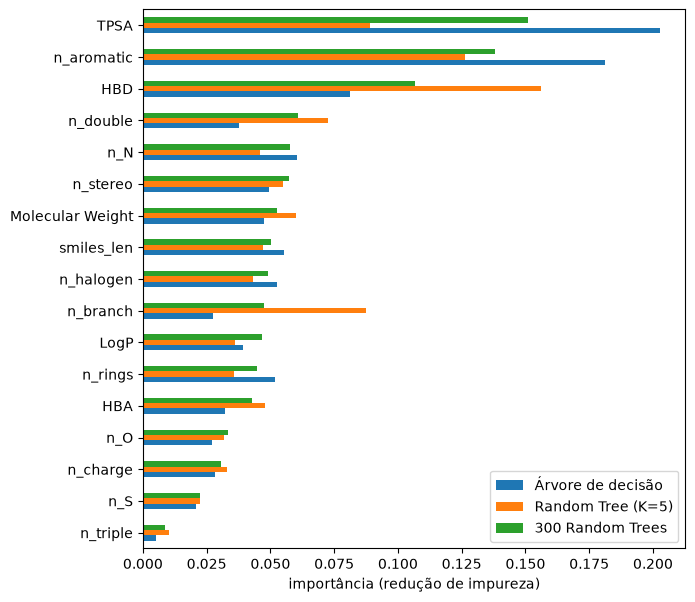

,Árvore de decisão,Random Tree (K=5),300 Random Trees
TPSA,0.203,0.089,0.151
n_aromatic,0.181,0.126,0.138
HBD,0.081,0.156,0.107
n_double,0.038,0.073,0.061
n_N,0.060,0.046,0.058
n_stereo,0.049,0.055,0.057
Molecular Weight,0.048,0.060,0.053
smiles_len,0.055,0.047,0.050
n_halogen,0.053,0.043,0.049
n_branch,0.027,0.087,0.048


In [20]:
importancias = pd.DataFrame(
    {nome: modelo.feature_importances_ for nome, modelo in modelos_finais.items()},
    index=atributos,
).sort_values("300 Random Trees")

importancias.plot.barh(figsize=(7, 7))
plt.xlabel("importância (redução de impureza)")
plt.show()

importancias.sort_values("300 Random Trees", ascending=False).round(3)

**Resultado.** A árvore de decisão reproduz o notebook 03 (568 erros, 28,7% deles no par HDAC1 ↔ EGFR). A votação de 300 Random Trees reduz os erros para 242 (−57%) e reduz 1 − F1 em cerca de 57% em cada classe, quase por igual; HDAC1 ganha mais pontos de F1 (+7,4) porque tinha mais erros, mas continua sendo a classe mais difícil (0,942).

O par HDAC1 ↔ EGFR cai na mesma proporção (163 → 72 erros) e passa de 28,7% para 29,8% dos erros: continua sendo a principal confusão. A votação corrige os erros de azar de cada árvore, mas não os que vêm do limite da representação; as contagens de SMILES não distinguem o grupo C(=O)NO dos inibidores de HDAC1.

Na Random Tree, a importância da TPSA cai de 0,203 para 0,089, porque ela só é sorteada em cerca de 29% dos nós; o crédito vai para atributos correlacionados, sobretudo HBD (0,081 → 0,156), a raiz dessa árvore. Nas 300 Random Trees, a TPSA volta ao primeiro lugar (0,151) e a importância fica mais bem distribuída entre os atributos.